# Statistical Analysis: A/B Testing for LLM Evaluation

*Added from the portal lesson.*

## How to use this notebook

Model A scores 0.72, model B scores 0.75. Is B really better? This notebook answers four questions a client will ask you:

| Part | The client asks | Sections |
|---|---|---|
| 1 | "Model B scored higher. Is it really better?" | 1, 2, 2a, 3, 3a |
| 2 | "Which test should we use?" | 4, 4a, 4b |
| 3 | "Do we have enough examples?" | 3b, 5 |
| 4 | "It's real. But is it worth it?" | 7, 8 |

Cells marked *Added from the portal lesson* bring in the parts of the lesson that the original notebook did not cover. **You don't need to memorise the maths.** Focus on what each result means for a client.

In [2]:
import numpy as np                 # numbers and random draws
import matplotlib.pyplot as plt    # charts
import scipy.stats as stats        # the statistical tests
rng = np.random.default_rng(42)    # random generator with a fixed "seed"
plt.rcParams["figure.figsize"] = (8, 4)

## 1. The problem: comparing averages

Model A scores 0.72, Model B scores 0.75. Is B actually better, or is this just noise?

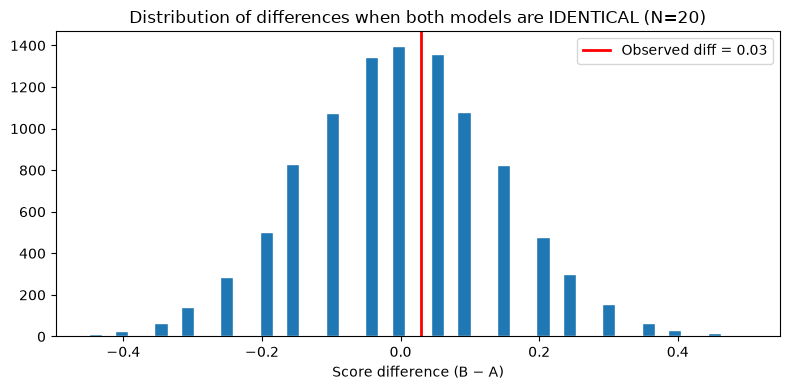

P(|diff| ≥ 0.03) by pure chance = 86.02%


In [3]:
# Simulate two models that are IDENTICAL (same true accuracy = 0.72)
# Each evaluated on N=20 examples
N = 20
TRUE_ACC = 0.72
N_SIMULATIONS = 10_000

differences = []
for _ in range(N_SIMULATIONS):
    a = rng.binomial(1, TRUE_ACC, N).mean()
    b = rng.binomial(1, TRUE_ACC, N).mean()
    differences.append(b - a)

differences = np.array(differences)

plt.hist(differences, bins=50, edgecolor="white")
plt.axvline(0.03, color="red", linewidth=2, label="Observed diff = 0.03")
plt.xlabel("Score difference (B − A)")
plt.title(f"Distribution of differences when both models are IDENTICAL (N={N})")
plt.legend()
plt.tight_layout()
plt.show()

p_at_least_3pts = np.mean(np.abs(differences) >= 0.03)
print(f"P(|diff| ≥ 0.03) by pure chance = {p_at_least_3pts:.2%}")

*Added from the portal lesson.*

**What you see:** two **identical** models get different scores in about **86%** of the runs. With 20 pass/fail questions, scores move in steps of 5 points, so any gap at all counts as "≥ 0.03".

(The portal text says about 25%. The simulation above shows the real number, and it makes the point even stronger.)

**Key idea: a score is an estimate, not a fact.** Another 20 questions would give another score, with the same model. The real question is always: *is the difference bigger than luck alone would give us?*

## 2. Effect of sample size

The spread of the distribution depends on **N** and **variance**. More samples → narrower distribution → easier to detect real differences.

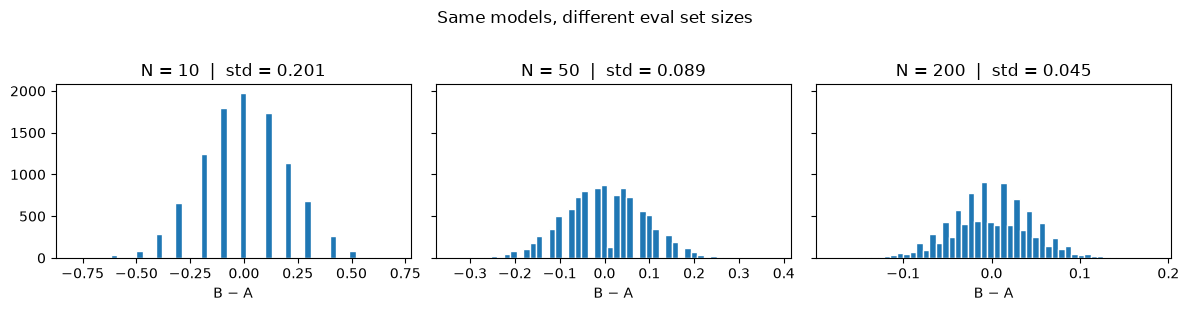

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)

for ax, n in zip(axes, [10, 50, 200]):
    diffs = []
    for _ in range(N_SIMULATIONS):
        a = rng.binomial(1, TRUE_ACC, n).mean()
        b = rng.binomial(1, TRUE_ACC, n).mean()
        diffs.append(b - a)
    ax.hist(diffs, bins=50, edgecolor="white")
    ax.set_title(f"N = {n}  |  std = {np.std(diffs):.3f}")
    ax.set_xlabel("B − A")

plt.suptitle("Same models, different eval set sizes", y=1.02)
plt.tight_layout()
plt.show()

*Added from the portal lesson.*

## 2a. The range of one score (confidence interval)

A single score needs a **range**: the **confidence interval**. It says where the model's real score (on thousands of questions) very probably is, usually with 95% confidence.

Below: a model gets **75%** right. Same score, three test sizes.

In [5]:
for correct, n in [(15, 20), (150, 200), (1500, 2000)]:
    ci = stats.binomtest(correct, n).proportion_ci(confidence_level=0.95)
    print(f"{correct}/{n} = {correct/n:.0%}   95% range: {ci.low:.0%} – {ci.high:.0%}")

15/20 = 75%   95% range: 51% – 91%
150/200 = 75%   95% range: 68% – 81%
1500/2000 = 75%   95% range: 73% – 77%


*Added from the portal lesson.*

**What it means:** with 20 questions, 75% really means "somewhere between about 51% and 91%". Too wide to decide anything. More data doesn't change the score, it changes **how sure you can be**.

Two honest options for a client: **get more data**, or **report the range**, e.g. "75% (51–91%), 20 questions".

*confidence interval = the range where the real score very probably is*

## 3. The t-statistic from scratch

The t-statistic standardises the observed difference by the uncertainty (standard error).  
$$t = \frac{\bar{x}_B - \bar{x}_A}{\text{SE}_{\text{diff}}}$$

In [6]:
# Generate one concrete sample
n = 40
scores_a = rng.binomial(1, 0.72, n).astype(float)
scores_b = rng.binomial(1, 0.75, n).astype(float)  # B is slightly better

mean_diff = scores_b.mean() - scores_a.mean()
pooled_se = np.sqrt(scores_a.var(ddof=1)/n + scores_b.var(ddof=1)/n)
t_stat    = mean_diff / pooled_se

print(f"Mean A:     {scores_a.mean():.3f}")
print(f"Mean B:     {scores_b.mean():.3f}")
print(f"Difference: {mean_diff:.3f}")
print(f"Pooled SE:  {pooled_se:.3f}")
print(f"t-statistic:{t_stat:.3f}")

Mean A:     0.675
Mean B:     0.750
Difference: 0.075
Pooled SE:  0.102
t-statistic:0.734


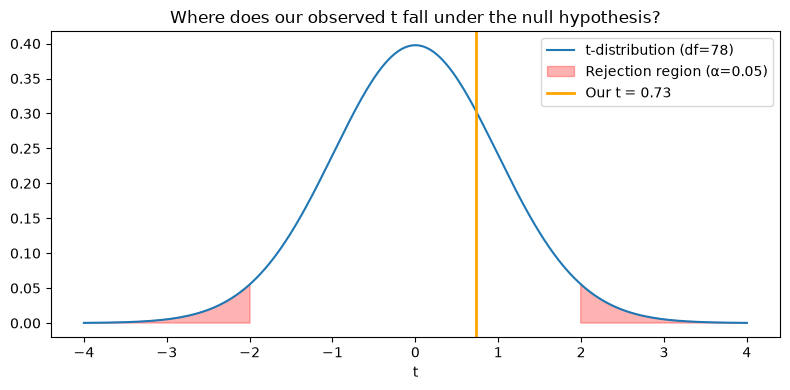

p-value: 0.4650
Reject H₀ (B = A)? No


In [7]:
# Visualise the t-distribution and where our t falls
df = 2 * n - 2  # degrees of freedom for two-sample test
x = np.linspace(-4, 4, 400)
y = stats.t.pdf(x, df)

plt.plot(x, y, label=f"t-distribution (df={df})")

# Shade the rejection regions (two-tailed, α=0.05)
crit = stats.t.ppf(0.975, df)
plt.fill_between(x, y, where=np.abs(x) > crit, alpha=0.3, color="red", label=f"Rejection region (α=0.05)")
plt.axvline(t_stat, color="orange", linewidth=2, label=f"Our t = {t_stat:.2f}")

plt.xlabel("t")
plt.legend()
plt.title("Where does our observed t fall under the null hypothesis?")
plt.tight_layout()
plt.show()

p_value = 2 * stats.t.sf(abs(t_stat), df)
print(f"p-value: {p_value:.4f}")
print("Reject H₀ (B = A)?" , "Yes" if p_value < 0.05 else "No")

*Added from the portal lesson.*

## 3a. What the p-value means, and what it does NOT

Every test asks one question: **if there were no real difference, how often would luck alone give a result at least this big?** That number is the **p-value**.

A coin example: a normal coin gives a result at least as far from 5–5 as "6 heads out of 10" very often, and "10 out of 10" almost never:

In [8]:
for heads in [6, 10]:
    p = stats.binomtest(heads, 10, 0.5).pvalue
    print(f"{heads} heads out of 10 -> p = {p:.3f}")

6 heads out of 10 -> p = 0.754
10 heads out of 10 -> p = 0.002


*Added from the portal lesson.*

- **p below 0.05** (the line called **alpha, α**): luck rarely gives this, so the difference is **probably real** ("statistically significant").
- **p above 0.05**: luck could easily give this, so **we can't tell**.

The 0.05 line is a convention, not a law of nature. Some fields are much stricter (particle physics uses about 0.0000003).

**What a p-value is NOT:**
1. It is **not** the probability that the models are identical.
2. It is **not** the probability that you are wrong.
3. It does **not** tell you how **big** the difference is (see section 7).
4. It does **not** guarantee you get the same result next time.

## 3b. What does the t-boundary mean in score space?

The critical t-value translates into a **minimum detectable difference** in the original score units.  
This makes the rejection threshold concrete: *"with N=50, you need at least X points gap to call it significant."*

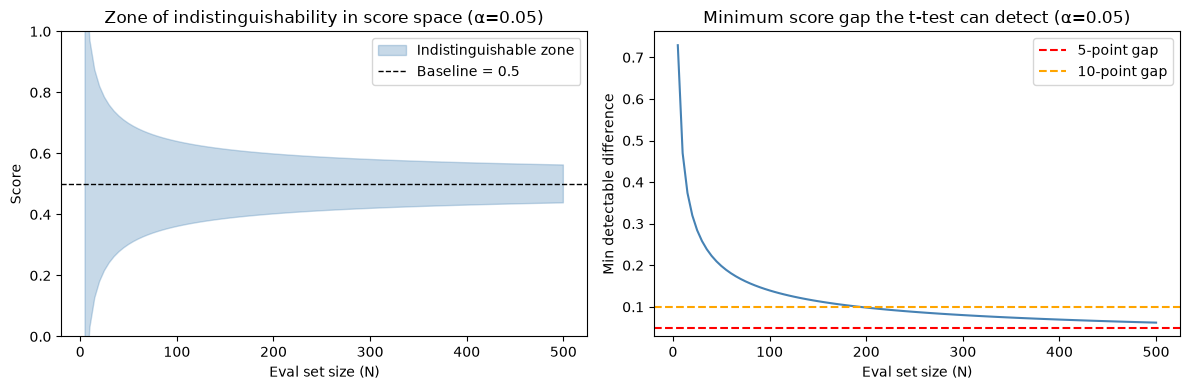

N   | Min detectable difference
----|---------------------------
  10 | 0.470
  20 | 0.320
  50 | 0.198
 100 | 0.139
 200 | 0.098
 400 | 0.069


In [9]:
base_score = 0.5   # assume binary scores centred at 0.5 (worst case variance)
alpha = 0.05
ns = np.arange(5, 501, 5)

# For each N: critical t × pooled SE → minimum detectable difference in score units
min_diffs = []
for n in ns:
    t_crit = stats.t.ppf(1 - alpha / 2, df=2 * n - 2)
    se = np.sqrt(2 * base_score * (1 - base_score) / n)  # pooled SE for binary scores
    min_diffs.append(t_crit * se)

min_diffs = np.array(min_diffs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Left: zone of indistinguishability in score space
ax1.fill_between(ns, base_score - min_diffs, base_score + min_diffs,
                 alpha=0.3, color="steelblue", label="Indistinguishable zone")
ax1.axhline(base_score, color="black", linestyle="--", linewidth=1, label=f"Baseline = {base_score}")
ax1.set_xlabel("Eval set size (N)")
ax1.set_ylabel("Score")
ax1.set_title("Zone of indistinguishability in score space (α=0.05)")
ax1.set_ylim(0, 1)
ax1.legend()

# Right: minimum detectable gap as a function of N
ax2.plot(ns, min_diffs, color="steelblue")
ax2.axhline(0.05, color="red",    linestyle="--", label="5-point gap")
ax2.axhline(0.10, color="orange", linestyle="--", label="10-point gap")
ax2.set_xlabel("Eval set size (N)")
ax2.set_ylabel("Min detectable difference")
ax2.set_title("Minimum score gap the t-test can detect (α=0.05)")
ax2.legend()

plt.tight_layout()
plt.show()

print("N   | Min detectable difference")
print("----|---------------------------")
for n in [10, 20, 50, 100, 200, 400]:
    t_crit = stats.t.ppf(0.975, df=2 * n - 2)
    se = np.sqrt(2 * base_score * (1 - base_score) / n)
    print(f"{n:4d} | {t_crit * se:.3f}")

*Added from the portal lesson.*

**How to read this table:** these numbers are the **smallest gap that can ever be significant** with N examples per model. Any smaller gap falls in the "zone of indistinguishability": the test can't tell it from luck. That's not because the models are the same, but because you don't have enough data to see it.

## 4. Choosing the right test

The t-test assumes approximately Gaussian data. LLM evaluations produce many other distributions — pick the test that matches the data generating process.

| Assumed distribution | LLM evaluation example | Standard test | Alternative |
|---|---|---|---|
| **Gaussian** | Average score (continuous judge output) | Welch's t-test | Student's t-test |
| **Binomial** | Binary correctness (pass/fail per example) | Fisher's exact test | Barnard's exact test |
| **Poisson** | Token count / tool calls per response | Poisson E-test | C-test |
| **Multinomial** | Error category counts (factual / incomplete / off-topic) | Chi-squared test | G-test |
| **Unknown** | Human Likert ratings, latency | Mann–Whitney U | Kruskal–Wallis (3+ groups) |

**Fisher's exact test** is particularly relevant here: our binary correctness scores (0/1) from `client.evaluate()` are Binomial, not Gaussian. The t-test is an approximation; Fisher's is exact.

*Added from the portal lesson.*

**Two notes from the lesson:**

- **Same questions for both models?** Then use the **paired** version of the test: **McNemar's test** for right/wrong, the **paired t-test** for 0.0–1.0 scores, **Wilcoxon signed-rank** for 1–5 ratings. LangSmith gives you paired data automatically when both models run on the same dataset. (See 4b.)
- **t-test on 0/1 scores:** not always wrong, but **less exact**, and that matters most on **small** tests. See the comparison after the next two cells.

In [10]:
from scipy.stats import fisher_exact, barnard_exact

# --- Binomial: binary correctness scores ---
# gpt-4o-mini: 15 correct out of 50  |  gpt-4o: 22 correct out of 50
n = 50
correct_mini, correct_4o = 15, 22

# Contingency table: [[correct_A, incorrect_A], [correct_B, incorrect_B]]
table = [
    [correct_mini, n - correct_mini],
    [correct_4o,   n - correct_4o],
]

odds_ratio, p_fisher = fisher_exact(table, alternative="two-sided")
print("=== Binomial: binary correctness (Fisher's exact) ===")
print(f"  gpt-4o-mini: {correct_mini}/{n}  |  gpt-4o: {correct_4o}/{n}")
print(f"  Odds ratio: {odds_ratio:.3f}")
print(f"  p-value:    {p_fisher:.4f}  → {'significant' if p_fisher < 0.05 else 'not significant'}")

# Barnard's test — slightly more powerful for unpaired 2×2 tables (no fixed margins)
res_barnard = barnard_exact(table, alternative="two-sided")
print(f"\n  Barnard's exact p-value: {res_barnard.pvalue:.4f}")
print("  (Barnard does not assume fixed row AND column totals — less conservative)")

=== Binomial: binary correctness (Fisher's exact) ===
  gpt-4o-mini: 15/50  |  gpt-4o: 22/50
  Odds ratio: 0.545
  p-value:    0.2137  → not significant

  Barnard's exact p-value: 0.1686
  (Barnard does not assume fixed row AND column totals — less conservative)


In [11]:
from scipy.stats import chi2_contingency, poisson_means_test, mannwhitneyu

# --- Multinomial: error category counts ---
# How often does each model produce each error type?
#                 factual  incomplete  off-topic
error_counts = np.array([
    [30, 15, 5],   # gpt-4o-mini
    [20, 25, 5],   # gpt-4o
])

chi2, p_chi2, dof, _ = chi2_contingency(error_counts)
G,    p_g,    _,   _ = chi2_contingency(error_counts, lambda_="log-likelihood")

print("=== Multinomial: error category distribution ===")
print(f"  Chi-squared: χ²={chi2:.3f}, p={p_chi2:.4f}, dof={dof}")
print(f"  G-test:       G={G:.3f},   p={p_g:.4f}")
print("  (G-test is preferred when expected counts are small)\n")

# --- Poisson: token counts per response ---
# Total tokens across 50 responses: mini=6000 tokens, 4o=4750 tokens
res_poisson = poisson_means_test(6000, 50, 4750, 50)

print("=== Poisson: token count per response ===")
print(f"  gpt-4o-mini: 6000 tokens / 50 calls = {6000/50:.0f} avg")
print(f"  gpt-4o:      4750 tokens / 50 calls = {4750/50:.0f} avg")
print(f"  Poisson E-test: p={res_poisson.pvalue:.4f}  → {'significant' if res_poisson.pvalue < 0.05 else 'not significant'}\n")

# --- Unknown distribution: human Likert ratings (1–5) ---
ratings_mini = rng.integers(1, 6, 40)   # human scores for model A
ratings_4o   = rng.integers(2, 6, 40)   # human scores for model B (slightly higher)

stat_mw, p_mw = mannwhitneyu(ratings_4o, ratings_mini, alternative="two-sided")

print("=== Unknown distribution: human Likert ratings ===")
print(f"  gpt-4o-mini mean rating: {ratings_mini.mean():.2f}")
print(f"  gpt-4o      mean rating: {ratings_4o.mean():.2f}")
print(f"  Mann-Whitney U: U={stat_mw:.1f}, p={p_mw:.4f}")
print("  (No normality assumption — ranks only)")

=== Multinomial: error category distribution ===
  Chi-squared: χ²=4.500, p=0.1054, dof=2
  G-test:       G=4.540,   p=0.1033
  (G-test is preferred when expected counts are small)

=== Poisson: token count per response ===
  gpt-4o-mini: 6000 tokens / 50 calls = 120 avg
  gpt-4o:      4750 tokens / 50 calls = 95 avg
  Poisson E-test: p=0.0000  → significant

=== Unknown distribution: human Likert ratings ===
  gpt-4o-mini mean rating: 2.98
  gpt-4o      mean rating: 3.42
  Mann-Whitney U: U=960.5, p=0.1136
  (No normality assumption — ranks only)


In [12]:
def t_vs_fisher(a_right, b_right, n):
    A = np.r_[np.ones(a_right), np.zeros(n - a_right)]
    B = np.r_[np.ones(b_right), np.zeros(n - b_right)]
    p_t = stats.ttest_ind(B, A, equal_var=False).pvalue
    p_f = fisher_exact([[a_right, n - a_right], [b_right, n - b_right]]).pvalue
    print(f"{n:4d} questions, A {a_right} vs B {b_right}:  t-test p = {p_t:.3f}   Fisher p = {p_f:.3f}")

t_vs_fisher(3, 8, 10)      # small test: the two tests disagree
t_vs_fisher(140, 170, 300) # big test: they agree

  10 questions, A 3 vs B 8:  t-test p = 0.024   Fisher p = 0.070
 300 questions, A 140 vs B 170:  t-test p = 0.014   Fisher p = 0.018


*Added from the portal lesson.*

**What it means:** on 10 questions the t-test says "real" (p < 0.05) and Fisher says "can't tell". On 300 questions both agree. **Rule: for right/wrong scores, use Fisher (or McNemar if paired).**

*Rule of thumb from class: if you're not sure the assumptions of the standard test hold, use the alternative test with fewer assumptions. It needs a bit more data, but it is less likely to fool you.*

## 4a. Using scipy — independent and paired t-tests

In [13]:
# Independent t-test: two separate groups of examples
t, p = stats.ttest_ind(scores_b, scores_a)
print(f"Independent t-test: t={t:.3f}, p={p:.4f}")

# Paired t-test: same examples evaluated by both models
# (reduces variance by removing per-example difficulty)
t_paired, p_paired = stats.ttest_rel(scores_b, scores_a)
print(f"Paired t-test:      t={t_paired:.3f}, p={p_paired:.4f}")

print("\nUse paired when both models answered the same questions.")
print("Paired tests are more powerful — they remove per-question difficulty noise.")

Independent t-test: t=0.734, p=0.4650
Paired t-test:      t=0.771, p=0.4456

Use paired when both models answered the same questions.
Paired tests are more powerful — they remove per-question difficulty noise.


*Added from the portal lesson.*

**The paired t-test in 4 steps:** (1) for each question, compute score_B − score_A; (2) take the average of those differences; (3) divide it by its standard error → the t-statistic; (4) look up the p-value. You are not asking "are the two groups different?" but "is the average difference per question bigger than zero?"

**Why the demo above shows no advantage:** the cell creates A's and B's answers **independently**, so there is no shared question difficulty to remove. Real questions are easy or hard **for both models**. Section 4b shows the difference.

## 4b. Paired data: only the disagreements count (McNemar)

ShopCo example: both models answer the **same 50 emails**.

In [14]:
both_right, both_wrong, only_a, only_b = 35, 5, 1, 9
n = both_right + both_wrong + only_a + only_b
a_right, b_right = both_right + only_a, both_right + only_b
print(f"A: {a_right}/{n} = {a_right/n:.0%}    B: {b_right}/{n} = {b_right/n:.0%}")

p_fisher = fisher_exact([[a_right, n - a_right], [b_right, n - b_right]]).pvalue
p_mcnemar = stats.binomtest(only_a, only_a + only_b).pvalue   # exact McNemar test
print(f"Independent test (Fisher): p = {p_fisher:.3f}")
print(f"Paired test (McNemar):     p = {p_mcnemar:.3f}   <- uses only the {only_a + only_b} disagreements")

A: 36/50 = 72%    B: 44/50 = 88%
Independent test (Fisher): p = 0.078
Paired test (McNemar):     p = 0.021   <- uses only the 10 disagreements


In [15]:
# Simulation: questions are easy or hard for BOTH models; B is really a bit better.
def paired_vs_independent(n=100, n_sim=1000):
    found_ind = found_pair = 0
    for _ in range(n_sim):
        p = rng.choice([0.05, 0.95], n, p=[0.35, 0.65])           # hard or easy question
        a = (rng.random(n) < p).astype(int)
        b = (rng.random(n) < np.clip(p + 0.08, 0, 0.99)).astype(int)
        found_ind += fisher_exact([[a.sum(), n - a.sum()], [b.sum(), n - b.sum()]]).pvalue < 0.05
        oa, ob = int(((a == 1) & (b == 0)).sum()), int(((a == 0) & (b == 1)).sum())
        found_pair += (oa + ob > 0) and stats.binomtest(oa, oa + ob).pvalue < 0.05
    print(f"Real improvement found -> independent test: {found_ind/n_sim:.0%}   paired test: {found_pair/n_sim:.0%}")

paired_vs_independent()

Real improvement found -> independent test: 0%   paired test: 31%


*Added from the portal lesson.*

**What it means:** same data, same scores. The paired test finds the real improvement far more often, because it ignores the questions both models got right or both got wrong. **Whenever you can, test both models on the same examples.**

*independent = each model gets different examples · paired = both models get the same examples*

## 5. Power and sample size

**Power** = probability of detecting a real difference when it exists.  
At what N can we reliably detect a 5-point improvement?

c:\Users\Denish\anaconda1\envs\bootcamp-env\Lib\site-packages\scipy\stats\_axis_nan_policy.py:592: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


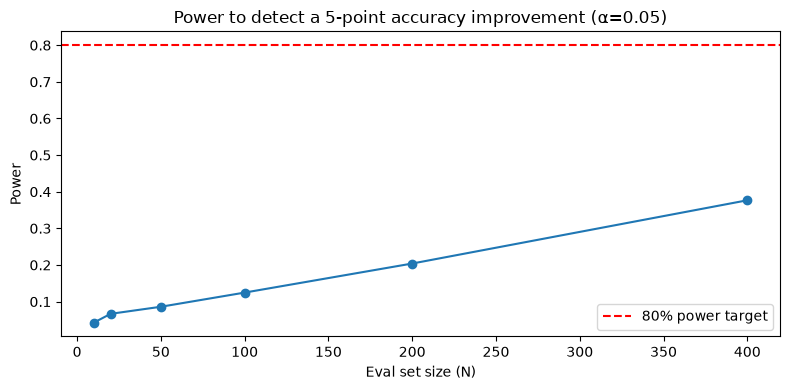

N=  10  power=0.04
N=  20  power=0.07
N=  50  power=0.09
N= 100  power=0.12
N= 200  power=0.20
N= 400  power=0.38


In [16]:
def empirical_power(true_diff, base_acc, n, n_sim=3000, alpha=0.05):
    """Simulate power: fraction of experiments that correctly reject H₀."""
    rejections = 0
    for _ in range(n_sim):
        a = rng.binomial(1, base_acc,            n).astype(float)
        b = rng.binomial(1, base_acc + true_diff, n).astype(float)
        _, p = stats.ttest_ind(b, a)
        if p < alpha:
            rejections += 1
    return rejections / n_sim

sample_sizes = [10, 20, 50, 100, 200, 400]
powers = [empirical_power(true_diff=0.05, base_acc=0.72, n=n) for n in sample_sizes]

plt.plot(sample_sizes, powers, marker="o")
plt.axhline(0.8, color="red", linestyle="--", label="80% power target")
plt.xlabel("Eval set size (N)")
plt.ylabel("Power")
plt.title("Power to detect a 5-point accuracy improvement (α=0.05)")
plt.legend()
plt.tight_layout()
plt.show()

for n, pw in zip(sample_sizes, powers):
    print(f"N={n:4d}  power={pw:.2f}")

*Added from the portal lesson.*

**What it means:** **power** = the chance that your test finds a difference that is really there. Think of a fishing net: few examples = big holes, only big fish (big differences) get caught. Target: **80%**.

With 20 examples, a real 5-point gain is found only a few times in 100. Teams then conclude "no difference" and throw away a better model. **"Not significant" does not mean "no difference".**

## 6. Applying to simulated LLM experiment scores

Standalone simulation that mirrors the LangSmith experiment from notebook 02.

In [17]:
# Simulate correctness scores from the two models on the same 20 HLE questions
N_EVAL = 20
model_mini_scores = rng.binomial(1, 0.35, N_EVAL).astype(float)  # gpt-4o-mini on PhD questions
model_4o_scores   = rng.binomial(1, 0.45, N_EVAL).astype(float)  # gpt-4o slightly better

print(f"gpt-4o-mini mean: {model_mini_scores.mean():.2f}")
print(f"gpt-4o      mean: {model_4o_scores.mean():.2f}")

t, p = stats.ttest_rel(model_4o_scores, model_mini_scores)
print(f"\nPaired t-test: t={t:.3f}, p={p:.4f}")

if p < 0.05:
    print("→ Significant at α=0.05: gpt-4o appears better on this benchmark.")
else:
    print(f"→ Not significant (p={p:.3f}). With N={N_EVAL} we likely don't have enough power.")
    print(f"   Recall: a 10-point difference needs about 300–400 examples per model for 80% power.")

gpt-4o-mini mean: 0.35
gpt-4o      mean: 0.60

Paired t-test: t=1.561, p=0.1351
→ Not significant (p=0.135). With N=20 we likely don't have enough power.
   Recall: a 10-point difference needs about 300–400 examples per model for 80% power.


*Added from the portal lesson.*

## 7. Real, but is it worth it? (effect size)

The p-value says whether a difference is **real**. **Cohen's d** says how **big** it is: the difference between the two averages, divided by how much scores normally jump around.

| Cohen's d | Size |
|---|---|
| below 0.2 | negligible |
| 0.2 – 0.5 | small |
| 0.5 – 0.8 | medium |
| above 0.8 | large |

Read the two numbers **together**:
- **Large d, p above 0.05:** looks promising, too little data to confirm → **get more data**.
- **Tiny d, very small p:** real but tiny (huge tests see even tiny differences) → **probably not worth** the extra cost or latency.

*(For right/wrong scores, Cohen's h is the textbook version; d gives a similar picture.)*

## 8. Multiple comparisons

**The problem.** Every test has a small chance (5%) that **luck** makes a model look like a winner. One test = luck gets 1 chance. Ten tests = luck gets 10 chances. If you test 10 models at α = 0.05, you will often find a "winner" that is pure luck, even when all models are identical. **Test many, fool yourself.**

The fix is a **correction**: a rule that changes the cut-off line when you run many tests. You still run your normal test first (Fisher, McNemar, t-test), then the correction decides which p-values count as winners. There are two common ones.

### Bonferroni: one strict line for everyone
- **Rule:** divide 0.05 by the number of tests. 10 tests → each p-value must be below **0.005**. 20 tests → **0.0025**.
- **Like** a very strict airport scanner: almost nothing dangerous gets through, but some innocent people are stopped too.
- **Protects:** the chance of **even one** fake winner stays at about 5% (the *family-wise error rate*, FWER).
- **Price:** very strict, so you also **miss some real winners**.

### Benjamini-Hochberg (BH): a line that grows
- **Rule:** sort the p-values from smallest to largest. Each one gets its own line, which grows down the list: 1st < 0.005, 2nd < 0.010, 3rd < 0.015 … 10th < 0.05. Find the **last** p-value that is below its own line: that one and all above it are winners.
- **Like** fishing with a medium net: maybe 1 fish in 20 is the wrong fish, but you catch many more good ones.
- **Protects:** among your winners, only about **5% are fake** (the *false discovery rate*, FDR).
- **Price:** a few fake winners, but you **keep more real winners**.

### Same data, three answers
ShopCo tests 10 prompts against the current one. The p-values, sorted:

| # | p-value | No correction (< 0.05) | Bonferroni (< 0.005) | BH line | BH |
|---|---|---|---|---|---|
| 1 | 0.001 | ✅ | ✅ | 0.005 | ✅ |
| 2 | 0.004 | ✅ | ✅ | 0.010 | ✅ |
| 3 | 0.012 | ✅ | ❌ | 0.015 | ✅ |
| 4 | 0.021 | ✅ | ❌ | 0.020 | ❌ |
| 5 | 0.034 | ✅ | ❌ | 0.025 | ❌ |
| 6 | 0.048 | ✅ | ❌ | 0.030 | ❌ |
| 7–10 | 0.21 … 0.85 | ❌ | ❌ | 0.035 … 0.05 | ❌ |
| **Winners** | | **6** | **2** | | **3** |

No correction finds the most winners, but some are probably luck. Bonferroni is the strictest. BH is in the middle.

### Which one should you use?
| Situation | Use | Why |
|---|---|---|
| **One** test, planned before starting | No correction | Luck has only one chance |
| The winner goes **live** (bank, hospital) | **Bonferroni** | A fake winner is expensive or dangerous |
| **Exploring** many ideas; the best will be tested again | **BH** | Missing a real winner is the bigger loss |

**Remember:** Bonferroni = almost never fooled, but misses some good ones. BH = fooled a little, but finds more good ones. Choose **before** you see the p-values.

**The code below:** we make 10 models that are **all exactly as good** as the baseline, test each one, and repeat the whole experiment 5,000 times. We count how often at least one model looks like a winner: with no correction, with Bonferroni, and with BH.


In [18]:
from scipy.stats import false_discovery_control

N_MODELS   = 10
N_EXAMPLES = 50
TRUE_PERF  = 0.60
N_SIM      = 5000
ALPHA      = 0.05

fp_raw        = []
fp_bonferroni = []
fp_fdr        = []

baseline = rng.binomial(1, TRUE_PERF, (N_SIM, N_EXAMPLES)).astype(float)

for sim in range(N_SIM):
    a = baseline[sim]
    p_values = []
    for _ in range(N_MODELS):
        b = rng.binomial(1, TRUE_PERF, N_EXAMPLES).astype(float)
        _, p = stats.ttest_ind(b, a)
        p_values.append(p)

    p_values = np.array(p_values)

    # Uncorrected: any test below α
    fp_raw.append(np.any(p_values < ALPHA))

    # Bonferroni: divide α by number of tests
    fp_bonferroni.append(np.any(p_values < ALPHA / N_MODELS))

    # Benjamini-Hochberg FDR: adjust p-values, then threshold at α
    adjusted = false_discovery_control(p_values, method="bh")
    fp_fdr.append(np.any(adjusted < ALPHA))

print(f"Uncorrected:  {np.mean(fp_raw):.2%}  false positive rate")
print(f"Bonferroni:   {np.mean(fp_bonferroni):.2%}  false positive rate  (controls: P(any FP) ≤ α)")
print(f"BH-FDR:       {np.mean(fp_fdr):.2%}  false positive rate  (controls: E[FP / rejections] ≤ α)")
print()
print(f"Theory: uncorrected ≈ {1 - (1-ALPHA)**N_MODELS:.2%} | Bonferroni ≈ {ALPHA:.2%} | FDR ≈ {ALPHA:.2%} (but less power lost)")


Uncorrected:  30.16%  false positive rate
Bonferroni:   4.36%  false positive rate  (controls: P(any FP) ≤ α)
BH-FDR:       4.86%  false positive rate  (controls: E[FP / rejections] ≤ α)

Theory: uncorrected ≈ 40.13% | Bonferroni ≈ 5.00% | FDR ≈ 5.00% (but less power lost)


*Added from the portal lesson.*

**What you see:** 10 models that are **all identical** to the baseline. Without correction, about **3 in 10** experiments still crown a "winner" that is pure luck. Theory says 40%; the simulation shows less (≈ 30%) because all 10 models are compared with the **same** baseline, so the tests are not independent. Both numbers say the same thing: **test many, fool yourself.**

**Which correction?**
- **Bonferroni** (α ÷ number of tests): very strict. Use when one false winner is expensive or dangerous (a bank, a hospital, a model going to production). Price: you miss some real winners.
- **Benjamini-Hochberg (BH)**: accepts a few false winners to find more real ones. Use when you explore (shortlisting 10 prompts, then testing the best again).

*(Here everyone is identical, so every "win" is false: that's why Bonferroni and BH look the same, ≈ 5%. They differ when some models are really better: BH keeps more of them.)*


## 9. Summary: what to report

| Metric | Why |
|---|---|
| Mean ± 95% CI | Central tendency + uncertainty |
| N (eval set size) | Determines power |
| Which test, and why | Lets others check your choice (e.g. McNemar: right/wrong, paired) |
| p-value | How often luck alone would give this result |
| Cohen's d (effect size) | Practical significance |
| Latency & token count | Efficiency (from slides: report it!) |

**Saturation caveat**: if all models score >95%, the benchmark tells you nothing useful — a score of 96 vs 97 is noise.

In [19]:
def bootstrap_mean_diff(a, b, n_boot=10_000):
    """Paired bootstrap: resample the same questions for both models."""
    idx = rng.integers(0, len(a), (n_boot, len(a)))
    return b[idx].mean(axis=1) - a[idx].mean(axis=1)

def size_label(d):
    d = abs(d)
    return "negligible" if d < 0.2 else "small" if d < 0.5 else "medium" if d < 0.8 else "large"

# Cohen's d for effect size
def cohens_d(a, b):
    pooled_std = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return (b.mean() - a.mean()) / pooled_std if pooled_std > 0 else 0.0

d = cohens_d(model_mini_scores, model_4o_scores)
t, p = stats.ttest_rel(model_4o_scores, model_mini_scores)
ci_low, ci_high = np.percentile(bootstrap_mean_diff(model_mini_scores, model_4o_scores), [2.5, 97.5])

print("=== Evaluation Report ===")
print(f"Model A (gpt-4o-mini):  mean={model_mini_scores.mean():.3f}  N={N_EVAL}")
print(f"Model B (gpt-4o):       mean={model_4o_scores.mean():.3f}  N={N_EVAL}")
print(f"Difference:             {model_4o_scores.mean() - model_mini_scores.mean():.3f}")
print(f"95% Bootstrap CI:       [{ci_low:.3f}, {ci_high:.3f}]")
print(f"Paired t-test p-value:  {p:.4f}")
print(f"Cohen's d:              {d:.3f}  ({size_label(d)})")

=== Evaluation Report ===
Model A (gpt-4o-mini):  mean=0.350  N=20
Model B (gpt-4o):       mean=0.600  N=20
Difference:             0.250
95% Bootstrap CI:       [-0.050, 0.550]
Paired t-test p-value:  0.1351
Cohen's d:              0.504  (medium)


*Added from the portal lesson.*

**A complete result looks like this:** "Model B 88% (76–94%) vs model A 72% (58–83%) · 50 emails, the same for both · McNemar test (right/wrong, paired) · p = 0.02 · d = 0.4 (small) · B: +0.3 s per answer, 2× tokens." Not just "p = 0.02".

**Saturation:** if both models score above 95%, the test can't tell them apart. Don't run more statistics: find a harder test.

## Five common mistakes

| Mistake | Fix |
|---|---|
| Testing on 20 examples and reporting a p-value | Decide the size first (3b, 5) |
| t-test on right/wrong scores | Fisher, or McNemar if paired (4, 4b) |
| Stopping when it looks significant (peeking) | Fixed size, run once |
| Reporting only the p-value | Range, N, test + why, p, d, latency, cost (9) |
| "Not significant" = "no difference" | Maybe the net had big holes (5) |

## Before the lab
1. Write down the **smallest improvement** you care about.
2. Check your data is **big enough** to see it (3b).
3. Then run your test **once**.

**Further reading:** SciPy stats documentation · G*Power (free sample-size calculator) · *Beyond Accuracy: Behavioral Testing of NLP Models* (CheckList paper)